# Step 9: Second Phase 1 task, Public Coverage

The same pipeline and the same audit modules, run on a second Folktables task that is closer to welfare than the income threshold.

| | Income task (notebooks 01 to 08) | Public coverage task (this notebook) |
|---|---|---|
| Question | Is income above $50,000? | Does this person have public health coverage? |
| Population | working adults | people under 65 with income up to $30,000 |
| Direction | high income = 1 | covered by a welfare-type programme = 1 |
| Features | 10 | 19, including income (`PINCP`) and disability (`DIS`) |
| Protected attributes | race, sex | race, sex, **disability** |
| Sensitive features | race, sex, birthplace | race, sex, disability, citizenship, nativity |

Nothing in the audit code changes. The new task is passed in as a task definition (`src/tasks.py`), and the income task stays the default, so the dashboard and notebooks 01 to 08 are untouched.

Same limits as before: the label is still a proxy (coverage is an outcome, not a rule), one state, one year, one model, and all thresholds are documented defaults.

In [1]:
import sys, os, json
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.tasks import PUBLIC_COVERAGE as TASK
from src.data_pipeline import load_acs_income, build_public_coverage_task, clean_features, train_test_split_with_group
from src.model import build_dtypes, apply_dtypes, train_baseline, evaluate
from src.audit.data_quality import audit_data_quality_result
from src.audit.run_all import run_all_audits
from src.audit.grs import grs_sensitivity
from src.audit.common import save_result

OUT = os.path.abspath("../results/public_coverage")
PROC = os.path.abspath("../data/processed/public_coverage")
os.makedirs(OUT, exist_ok=True)
os.makedirs(PROC, exist_ok=True)

## 1. Load and build the task

Same California 2022 download as before (cached). Folktables keeps people under 65 with income of $30,000 or less and builds the label `PUBCOV` (public coverage = 1).

In [2]:
acs = load_acs_income(state="CA", year="2022")
features, label, group = build_public_coverage_task(acs)
print("Rows x features:", features.shape)
print("Share with public coverage:", round(label.mean(), 4))
features.head()

Rows x features: (129306, 19)
Share with public coverage: 0.4045


,AGEP,SCHL,MAR,SEX,DIS,ESP,CIT,MIG,MIL,ANC,NATIVITY,DEAR,DEYE,DREM,PINCP,ESR,ST,FER,RAC1P
0,56.0,17.0,5.0,2.0,1.0,0.0,1.0,1.0,4.0,1.0,1.0,2.0,2.0,1.0,14500.0,6.0,6.0,0.0,1.0
1,52.0,1.0,5.0,1.0,1.0,0.0,5.0,1.0,4.0,1.0,2.0,2.0,1.0,2.0,0.0,6.0,6.0,0.0,8.0
2,61.0,19.0,4.0,1.0,1.0,0.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,80.0,6.0,6.0,0.0,1.0
3,26.0,19.0,5.0,2.0,1.0,0.0,4.0,1.0,4.0,1.0,2.0,2.0,2.0,1.0,9000.0,1.0,6.0,2.0,8.0
4,23.0,16.0,5.0,1.0,2.0,0.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,24000.0,4.0,6.0,0.0,9.0


## 2. Understand the data (EDA)

Same questions as notebook 01: balance, group sizes, base rates before any model, and what the raw values look like.

In [3]:
print("Label balance:")
print(label.value_counts(normalize=True).rename("proportion"))

view = pd.concat([features[["RAC1P", "SEX", "DIS"]], label.rename("label")], axis=1)
for col in ("RAC1P", "SEX", "DIS"):
    print(f"\nPublic-coverage rate by {col}:")
    print(view.groupby(col)["label"].agg(["mean", "count"]).round(4))

Label balance:
label
False    0.595471
True     0.404529
Name: proportion, dtype: float64

Public-coverage rate by RAC1P:
         mean  count
RAC1P               
1.0    0.3614  43099
2.0    0.5505   7045
3.0    0.4541   2123
4.0    0.4211     19
5.0    0.4596    470
6.0    0.3180  20803
7.0    0.3992    521
8.0    0.4778  29525
9.0    0.4176  25701

Public-coverage rate by SEX:
       mean  count
SEX               
1.0  0.4208  58077
2.0  0.3913  71229

Public-coverage rate by DIS:
       mean   count
DIS                
1.0  0.7019   18494
2.0  0.3549  110812


**New in this task: hidden gaps.** Many answers do not apply to everyone (for example, school-related questions for adults, or military service for children), so the raw survey has empty values there. Folktables then replaces every empty value with `0`. (Its code calls `np.nan_to_num(x, -1)`, where the `-1` is read as a different argument, so the fill value is the default `0`, not `-1`.) A `0` looks like a real answer, so the data-quality audit below cannot see these gaps. This table counts them in the raw data, before Folktables fills them.

In [4]:
from folktables import ACSPublicCoverage
raw = ACSPublicCoverage._preprocess(acs)[list(TASK.feature_cols)]
na = raw.isna().sum()
print("Empty values per column in the raw data (later filled with 0), non-zero only:")
print(na[na > 0].sort_values(ascending=False).to_frame("empty_rows").assign(share=lambda d: (d["empty_rows"] / len(raw)).round(3)))
print("\nDistinct values per column:")
print(features.nunique().sort_values(ascending=False).to_string())

Empty values per column in the raw data (later filled with 0), non-zero only:
     empty_rows  share
ESP      115983  0.897
FER       76835  0.594
MIL        9688  0.075
ESR        4863  0.038

Distinct values per column:
PINCP       1387
AGEP          50
SCHL          24
RAC1P          9
ESP            9
ESR            7
MAR            5
MIL            5
CIT            5
ANC            4
MIG            3
FER            3
NATIVITY       2
DIS            2
SEX            2
DREM           2
DEYE           2
DEAR           2
ST             1


## 3. Data quality, cleaning and split

Audit on the raw features first, then drop duplicates, then a stratified 80/20 split with the same seed.

**Read the duplicate rate with care.** Every row in this survey is a different person. Rows with identical feature values are people who share the same profile, not copied records, and with 19 coarse features in a low-income group many people do. So the duplicate rate here measures identical profiles, and removing them discards real people. The same applies, at a smaller scale (3.7%), to the income task. It is kept here for consistency with notebook 01, and it is the reason the data-quality dimension fails in this notebook.

In [5]:
dq = audit_data_quality_result(features)
print(dq.summary())

cleaned = clean_features(features)
lab = label.loc[cleaned.index]
grp = group.loc[cleaned.index]
print(f"\nRows before cleaning: {len(features):,}  after: {len(cleaned):,}  dropped: {len(features) - len(cleaned):,}")

split = train_test_split_with_group(cleaned, lab, grp)
print("Train:", split.X_train.shape, " Test:", split.X_test.shape)
split.X_train.assign(label=split.y_train, group=split.group_train).to_csv(os.path.join(PROC, "train.csv"), index=False)
split.X_test.assign(label=split.y_test, group=split.group_test).to_csv(os.path.join(PROC, "test.csv"), index=False)

Data quality: risk 1.000 (fail)
  - 129,306 rows audited: missing value rate 0.00%, duplicate rate 21.97%, completeness 100.00%.

Rows before cleaning: 129,306  after: 100,902  dropped: 28,404


Train: (80721, 19)  Test: (20181, 19)


## 4. Baseline model

The same XGBoost settings as the income model (300 trees, depth 6, learning rate 0.1), with native categorical handling.

In [6]:
dtypes = build_dtypes(split.X_train, split.X_test, TASK)
Xtr = apply_dtypes(split.X_train, dtypes, TASK)
Xte = apply_dtypes(split.X_test, dtypes, TASK)
yte = split.y_test.to_numpy()

model = train_baseline(Xtr, split.y_train)
p = model.predict_proba(Xte)[:, 1]
metrics = evaluate(yte, (p >= 0.5).astype(int), p)
pd.Series(metrics).round(4).rename("public_coverage_test").to_frame()

,public_coverage_test
accuracy,0.7000
precision,0.6795
recall,0.5073
f1,0.5809
roc_auc,0.7567


## 5. Run every audit and the Governance Risk Score

In [7]:
results, grs, _ = run_all_audits(model, Xte, y_true=yte, precomputed={"data_quality": dq}, task=TASK)
for r in results.values():
    print(r.summary(), "\n")

Data quality: risk 1.000 (fail)
  - 129,306 rows audited: missing value rate 0.00%, duplicate rate 21.97%, completeness 100.00%. 

Explainability: risk 1.000 (fail)
  - Most influential features: MAR (12.9%), ESR (12.9%), DIS (12.5%).
  - Sensitive features ['RAC1P', 'SEX', 'DIS', 'CIT', 'NATIVITY'] carry 24.6% of total SHAP importance (limit 10%). Read with the fairness module: this shows influence, not proof of discrimination.
  - 5.1% of decisions change when only SEX is changed (limit 5%).
  - 29.9% of decisions change when only RAC1P is changed (limit 5%).
  - 25.6% of decisions change when only DIS is changed (limit 5%). 

Robustness: risk 1.000 (fail)
  - noise (0.2): accuracy falls 2.1% relative; 12.5% of decisions change.
  - missing (0.1): accuracy falls 11.9% relative; 24.8% of decisions change.
  - swap (0.05): accuracy falls 0.9% relative; 3.6% of decisions change. 

Fairness: risk 1.000 (fail)
  - RAC1P: demographic parity difference 0.311 exceeds 0.10 (group 2.0 selected

In [8]:
print(f"GRS = {grs.score:.3f} ({grs.band}); worst dimension: {grs.worst_dimension}")
print("Failing dimensions:", grs.failing or "none")
grs.profile[["dimension", "risk", "status", "weight", "contribution"]].round(3)

GRS = 0.830 (Critical); worst dimension: Data quality
Failing dimensions: ['Data quality', 'Fairness', 'Explainability', 'Robustness']


,dimension,risk,status,weight,contribution
key,,,,,
data_quality,Data quality,1.000,fail,0.167,0.167
fairness,Fairness,1.000,fail,0.167,0.167
explainability,Explainability,1.000,fail,0.167,0.167
reliability,Reliability,0.484,pass,0.167,0.081
robustness,Robustness,1.000,fail,0.167,0.167
oversight,Human oversight,0.498,pass,0.167,0.083


## 6. Fairness detail, including disability

Disability is a protected characteristic that the income task did not have.

In [9]:
fm = results["fairness"].metrics
rows = [{"attribute": a, "selection_gap": m["demographic_parity_difference"], "disparate_impact": m["disparate_impact_ratio"],
         "equal_opportunity_diff": m["equal_opportunity_difference"], "fpr_gap": m["equalized_odds_fpr_difference"],
         "risk": m["attribute_risk"]} for a, m in fm.items()]
print(pd.DataFrame(rows).set_index("attribute").round(4))
for a, t in results["fairness"].details.items():
    print(f"\n{a}"); print(t.round(3))

           selection_gap  disparate_impact  equal_opportunity_diff  fpr_gap  \
attribute                                                                     
RAC1P             0.3112            0.3867                  0.3287   0.1911   
SEX               0.0086            0.9725                  0.0030   0.0084   
DIS               0.5214            0.3014                  0.4821   0.3642   

             risk  
attribute          
RAC1P      1.0000  
SEX        0.0689  
DIS        1.0000  

RAC1P
          n  selection_rate  true_rate    tpr    fpr  accuracy
group                                                         
1.0    6659           0.273      0.371  0.513  0.131     0.737
2.0    1143           0.507      0.520  0.707  0.291     0.708
3.0     397           0.375      0.453  0.528  0.249     0.650
4.0       5           0.600      0.400  1.000  0.333     0.800
5.0      86           0.349      0.477  0.537  0.178     0.686
6.0    3195           0.196      0.345  0.378  0.100    

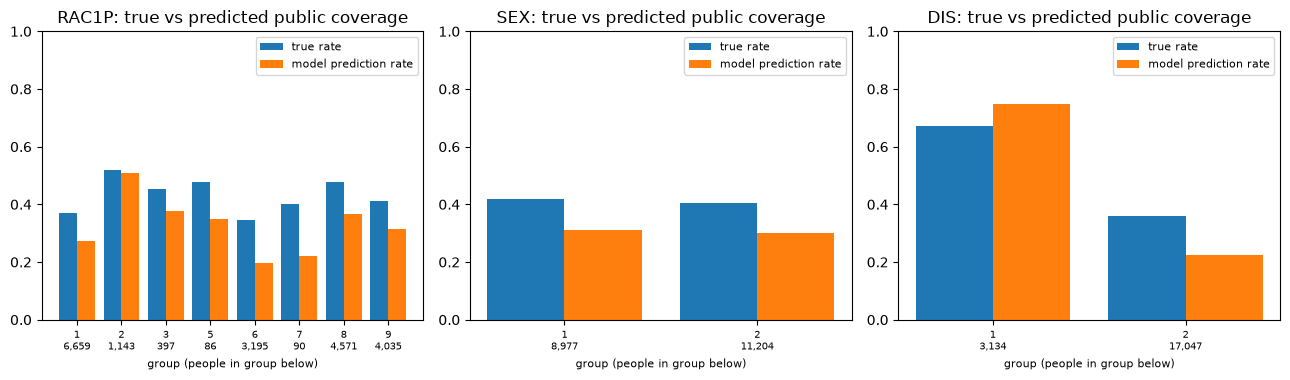

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (attr, table) in zip(axes, results["fairness"].details.items()):
    t = table[table.n >= 30]
    xx = np.arange(len(t))
    ax.bar(xx - 0.2, t["true_rate"], 0.4, label="true rate")
    ax.bar(xx + 0.2, t["selection_rate"], 0.4, label="model prediction rate")
    ax.set_xticks(xx)
    ax.set_xticklabels([f"{int(g)}\n{int(n):,}" for g, n in zip(t.index, t["n"])], fontsize=7)
    ax.set_xlabel("group (people in group below)", fontsize=8)
    ax.set_title(f"{attr}: true vs predicted public coverage")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Compare with the income task

The same six dimensions side by side. Both runs use equal weights and the same default thresholds.

In [11]:
with open(os.path.join(os.path.abspath("../results"), "grs_result.json")) as f:
    inc = json.load(f)
inc_prof = pd.DataFrame(inc["profile"]).set_index("dimension")[["risk", "status"]].add_prefix("income_")
pc_prof = grs.profile.set_index("dimension")[["risk", "status"]].add_prefix("coverage_")
cmp = inc_prof.join(pc_prof)
cmp.loc["GRS (overall)"] = [inc["grs"], inc["band"], grs.score, grs.band]
cmp

,income_risk,income_status,coverage_risk,coverage_status
dimension,,,,
Data quality,0.367390,pass,1.000000,fail
Fairness,1.000000,fail,1.000000,fail
Explainability,0.791000,fail,1.000000,fail
Reliability,0.325824,pass,0.484064,pass
Robustness,0.376435,pass,1.000000,fail
Human oversight,0.481600,pass,0.497745,pass
GRS (overall),0.557041,High,0.830302,Critical


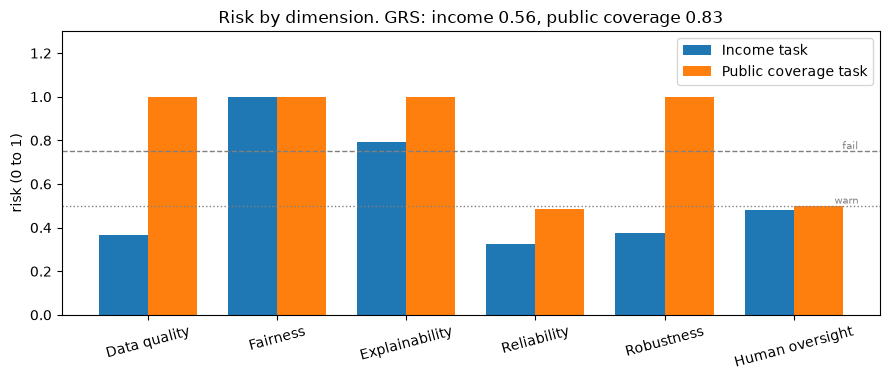

In [12]:
import matplotlib.pyplot as plt

dims = list(cmp.index[:-1])
x = np.arange(len(dims))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.bar(x - w / 2, cmp.loc[dims, "income_risk"].astype(float), w, label="Income task", color="tab:blue")
ax.bar(x + w / 2, cmp.loc[dims, "coverage_risk"].astype(float), w, label="Public coverage task", color="tab:orange")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.axhline(0.75, color="gray", ls="--", lw=1)
ax.text(len(dims) - 0.5, 0.51, "warn", fontsize=7, color="gray", ha="right")
ax.text(len(dims) - 0.5, 0.76, "fail", fontsize=7, color="gray", ha="right")
ax.set_xticks(x)
ax.set_xticklabels(dims, rotation=15)
ax.set_ylim(0, 1.3)
ax.set_ylabel("risk (0 to 1)")
g_inc = float(cmp.loc["GRS (overall)", "income_risk"])
g_cov = float(cmp.loc["GRS (overall)", "coverage_risk"])
ax.set_title(f"Risk by dimension. GRS: income {g_inc:.2f}, public coverage {g_cov:.2f}")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [13]:
grs_sensitivity(results).round(3)

,grs,band
weight_scheme,,
equal,0.830,Critical
fairness_heavy,0.857,Critical
technical_heavy,0.796,Critical
governance_heavy,0.823,Critical


## 8. Save everything

Saved to `results/public_coverage/` so it never overwrites the income results.

In [14]:
for key, r in results.items():
    save_result(r, os.path.join(OUT, f"{key}_result.json"))
model.save_model(os.path.join(OUT, "model.json"))
pd.Series(metrics).to_json(os.path.join(OUT, "metrics.json"), indent=2)
with open(os.path.join(OUT, "grs_result.json"), "w") as f:
    json.dump({"grs": grs.score, "band": grs.band, "worst_dimension": grs.worst_dimension, "failing": grs.failing,
               "profile": grs.profile.reset_index().to_dict(orient="records")}, f, indent=2,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved to", OUT)

Saved to E:\MTECH\Final_yr_project\results\public_coverage


## Summary

- Ran the unchanged pipeline and all six audits on a second, more welfare-like task.
- Added disability as a protected attribute and citizenship and nativity as sensitive features.
- Compared the two tasks dimension by dimension. Differences show what depends on the task, and agreement shows what does not.